# SAC × Ant-v5 from proposal to experiment

This self-contained experiment implements the Team 01 proposal using **Gymnasium, MuJoCo, and Stable-Baselines3 SAC**. Run the cells from top to bottom. The notebook contains the full experiment logic.

The default **smoke test runs 20 training episodes**. It checks network updates, the baseline, evaluation, serialization, and headless video rendering. Weight changes and nonzero losses confirm optimization. Assess gait quality and return improvements over a longer training budget.

Select `full` mode explicitly to run the full proposal budget of one million steps per seed, 10 baseline episodes, and a 10-episode evaluation every 50,000 steps. For three training seeds, set `SEEDS = [42, 43, 44]`.

References for the environment, algorithm, and implementation are [Ant-v5](https://gymnasium.farama.org/environments/mujoco/ant/), [Haarnoja et al. (2018), Soft Actor-Critic](https://arxiv.org/abs/1801.01290), [SB3 SAC](https://stable-baselines3.readthedocs.io/en/master/modules/sac.html), and [SAC in Spinning Up](https://spinningup.openai.com/en/latest/algorithms/sac.html).


## Worked example: one SAC critic update (no training needed)

This standalone toy example demonstrates one **value** update using the SAC soft Bellman target. Run the next cell by itself: it needs only Python, runs immediately and does not create an environment or change the trained model. The numbers are illustrative, not taken from an Ant episode.

For one transition, the soft Bellman target combines the reward with the minimum of the two target critics and an entropy term ([Haarnoja et al., 2018](https://arxiv.org/abs/1801.01290)):

$$y = r + \gamma \, (1 - \mathbb{1}[\text{terminated}]) \left( \min_{j=1,2} Q_j^{\text{tgt}}(s', \tilde{a}') - \alpha \log \pi(\tilde{a}' \mid s') \right)$$

Here `log_pi_next = -1.2` is the log probability density $\log \pi(\tilde{a}' \mid s')$ at a sampled next action, and `alpha` is the temperature that weights entropy. The two target-critic values are treated as fixed, as is the target during the critic gradient step.

We use a single scalar Q parameter and minimize the squared soft Bellman residual $L = (Q - y)^2$ with one plain gradient-descent step, $\nabla_Q L = 2\,(Q - y)$. This makes the arithmetic visible: actual SB3 SAC uses neural networks, batches, Adam and two critics, so this is an explanatory simplification, not a literal optimizer trace. A time-limit truncation is not automatically a terminal state for bootstrapping.


In [1]:
def toy_sac_critic_update():
    reward, gamma, alpha = 1.0, 0.99, 0.2
    q1_target, q2_target, log_pi_next = 4.0, 3.5, -1.2
    terminated = False  # this transition bootstraps from the next state

    q_before, learning_rate = 2.0, 0.1
    target = reward + gamma * (1 - int(terminated)) * (min(q1_target, q2_target) - alpha * log_pi_next)

    loss_before = (q_before - target) ** 2
    gradient = 2 * (q_before - target)  # derivative of squared loss w.r.t. scalar Q
    q_after = q_before - learning_rate * gradient
    loss_after = (q_after - target) ** 2

    return dict(target=target, q_before=q_before, q_after=q_after,
                loss_before=loss_before, loss_after=loss_after)


example = toy_sac_critic_update()

print(f"soft target y = {example['target']:.5f}")
print(f"Q before = {example['q_before']:.5f}; loss before = {example['loss_before']:.5f}")
print(f"Q after  = {example['q_after']:.5f}; loss after  = {example['loss_after']:.5f}")


soft target y = 4.70260
Q before = 2.00000; loss before = 7.30405
Q after  = 2.54052; loss after  = 4.67459


## Background training and live plots

To train from the terminal, run `.venv/bin/python train_sac.py`. The default budget is 20 episodes. See the tmux commands in `README.md` to run in a detachable session. The live dashboard shows elapsed time, estimated time remaining, throughput, episode count, and trends in reward, evaluation, and loss. For detailed plots, run `.venv/bin/python -m tensorboard.main --logdir artifacts --host 127.0.0.1 --port 6006`.

**To view background training, set `VIEW_BACKGROUND = True` and run only the next cell.** Set `AUTO_REFRESH = True` to update the plot every two seconds. You can rerun or stop the viewer independently of training. The ETA covers the current training seed up to the end of training and is approximate for episode-based budgets.

The stored outputs below come from the first smoke test. Use the viewer and its run directory under `artifacts/` for current results.

In [ ]:
VIEW_BACKGROUND = False
AUTO_REFRESH = False
RUN_TO_VIEW = None  # Use the latest background run or give its directory path.

if VIEW_BACKGROUND:
    from support.watch_sac import show_notebook
    background_state = show_notebook(RUN_TO_VIEW, auto_refresh=AUTO_REFRESH)


## Dependencies and reproducibility

The local Jupyter kernel uses `.venv`, which already has the dependencies. On a new machine, set `INSTALL_DEPS` to `True` and run the next cell, then **restart the kernel**, set the flag back to `False`, and run the notebook from the top. Install PyTorch for your platform if needed. The experiment requires zero data downloads or API keys.

The smoke test runs on the CPU with two threads. Small MLPs typically gain little from a GPU. By default, rendering uses headless EGL. On a machine without EGL, install the system OSMesa library and set `MUJOCO_GL=osmesa` before starting the kernel. The smoke test requires video and reports any rendering error.

In [1]:
INSTALL_DEPS = False

if INSTALL_DEPS:
    import subprocess, sys

    subprocess.check_call([sys.executable, '-m', 'pip', 'install',
        'gymnasium[mujoco]==1.2.1', 'stable-baselines3==2.7.0', 'mujoco==3.3.7',
        'imageio==2.37.0', 'imageio-ffmpeg==0.6.0',
        'matplotlib>=3.7,<4', 'pandas>=2,<3', 'ipykernel>=6,<7'])

    raise RuntimeError('Installation finished. Restart the kernel and set INSTALL_DEPS to False.')


In [2]:
import os

os.environ.setdefault('MUJOCO_GL', 'egl')  # Set before importing MuJoCo or Gymnasium.

import json, sys, time, random, platform
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version

import numpy as np
import pandas as pd
import torch
import gymnasium as gym
import matplotlib.pyplot as plt
import imageio.v2 as imageio

from IPython.display import display, Video
from stable_baselines3 import SAC
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback, EvalCallback, CallbackList
from stable_baselines3.common.env_checker import check_env

MODE = os.environ.get('ANT_SAC_MODE', 'smoke')  # Select full mode explicitly.
SEEDS = json.loads(os.environ.get('ANT_SAC_SEEDS', '[42]'))
DEVICE = 'cpu'
DASHBOARD = globals().get('DASHBOARD')  # The CLI supplies the optional dashboard.
RESUME_PATH = os.environ.get('ANT_SAC_RESUME')
assert MODE in ('smoke', 'full')
assert SEEDS and len(set(SEEDS)) == len(SEEDS)

CFG = dict(
    env_id='Ant-v5', max_episode_steps=1000,
    baseline_episodes=10, eval_episodes=10,
    train_episodes=20 if MODE == 'smoke' else None,
    total_timesteps=20_000 if MODE == 'smoke' else 1_000_000,
    eval_freq=250 if MODE == 'smoke' else 50_000,
    learning_starts=100 if MODE == 'smoke' else 10_000,
    buffer_size=50_000 if MODE == 'smoke' else 1_000_000,
    batch_size=64 if MODE == 'smoke' else 256,
    net_arch=[64, 64] if MODE == 'smoke' else [256, 256],
    learning_rate=3e-4, gamma=0.99, tau=0.005,
    train_freq=1, gradient_steps=1, video_max_steps=1000,
)

if MODE == 'smoke':
    CFG['train_episodes'] = int(os.environ.get('ANT_SAC_EPISODES', '20'))
    assert CFG['train_episodes'] > 0
    CFG['total_timesteps'] = CFG['train_episodes'] * CFG['max_episode_steps']
elif 'ANT_SAC_STEPS' in os.environ:
    CFG['total_timesteps'] = int(os.environ['ANT_SAC_STEPS'])

assert CFG['total_timesteps'] > CFG['learning_starts']
torch.set_num_threads(2)

RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN_DIR = Path(os.environ.get('ANT_SAC_OUTPUT', 'artifacts')) / f'ant_sac_{MODE}_{RUN_ID}'
RUN_DIR.mkdir(parents=True, exist_ok=False)

VERSIONS = {p: version(p) for p in ['gymnasium', 'mujoco', 'stable-baselines3',
    'torch', 'numpy', 'pandas', 'matplotlib', 'imageio', 'imageio-ffmpeg']}

METADATA = dict(mode=MODE, seeds=SEEDS, config=CFG, versions=VERSIONS,
    python=sys.version, executable=sys.executable, platform=platform.platform(),
    device=DEVICE, mujoco_gl=os.environ['MUJOCO_GL'], run_id=RUN_ID, resume_from=RESUME_PATH)
(RUN_DIR / 'config.json').write_text(json.dumps(METADATA, indent=2))

print('Python:', sys.executable, '\nOutput:', RUN_DIR.resolve())
print(json.dumps(METADATA, indent=2))


Python: /home/andreipc/Inno-RL/.venv/bin/python 
Output: /home/andreipc/Inno-RL/artifacts/ant_sac_smoke_20261021T184234215288Z
{
  "mode": "smoke",
  "seeds": [
    42
  ],
  "config": {
    "env_id": "Ant-v5",
    "max_episode_steps": 1000,
    "baseline_episodes": 10,
    "eval_episodes": 10,
    "train_episodes": 20,
    "total_timesteps": 20000,
    "eval_freq": 250,
    "learning_starts": 100,
    "buffer_size": 50000,
    "batch_size": 64,
    "net_arch": [
      64,
      64
    ],
    "learning_rate": 0.0003,
    "gamma": 0.99,
    "tau": 0.005,
    "train_freq": 1,
    "gradient_steps": 1,
    "video_max_steps": 1000
  },
  "versions": {
    "gymnasium": "1.2.1",
    "mujoco": "3.3.7",
    "stable-baselines3": "2.7.0",
    "torch": "2.5.1",
    "numpy": "2.2.6",
    "pandas": "2.3.3",
    "matplotlib": "3.10.9",
    "imageio": "2.37.0",
    "imageio-ffmpeg": "0.6.0"
  },
  "python": "3.10.19 (main, Oct 21 2025, 16:43:05) [GCC 11.2.0]",
  "executable": "/home/andreipc/Inno-RL/.

## Environment, reward, and method

The **105** observation values consist of 13 positions, 14 velocities, and 78 contact forces. The action has **8** continuous values in $[-1, 1]$. The explicit environment settings match the proposal. The reward is

$$r = r_{\text{healthy}} + r_{\text{forward}} - 0.5 \, r_{\text{ctrl}} - 0.0005 \, r_{\text{contact}}$$

An unhealthy state terminates the episode. The 1,000-step time limit truncates it.

SB3 uses `TimeLimit.truncated` to bootstrap the critic target at the time limit. Only true termination masks that term. SAC ([Haarnoja et al., 2018](https://arxiv.org/abs/1801.01290)) maximizes the entropy-regularized objective

$$J(\pi) = \mathbb{E}_{\tau \sim \pi} \left[ \sum_{t=0}^{\infty} \gamma^t \left( r(s_t, a_t) + \alpha \, H(\pi(\cdot \mid s_t)) \right) \right]$$

with two Q critics, target critics, a tanh-squashed Gaussian actor, and a learned temperature $\alpha$ (`ent_coef='auto'`). The critic learns against the soft Bellman target

$$y = r + \gamma \, (1 - \mathbb{1}[\text{terminated}]) \left( \min_{j=1,2} Q_j^{\text{tgt}}(s', \tilde{a}') - \alpha \log \pi(\tilde{a}' \mid s') \right)$$

The actor minimizes $\mathbb{E}[\alpha \log \pi(a \mid s) - \min_{j=1,2} Q_j(s, a)]$, and the target parameters follow the soft update $\theta^{\text{tgt}} \leftarrow \tau \theta + (1 - \tau) \, \theta^{\text{tgt}}$ with $\tau = 0.005$.

The smoke test changes the budget, network size, and batch size. Both modes use the same task and reward and use raw observations and rewards. The baseline, initial SAC policy, and final SAC policy share evaluation reset seeds. Evaluation runs without model updates. Training, periodic evaluation, and final evaluation each use separate seeds. The reported `std` is the standard deviation.


In [3]:
def make_env(render_mode=None):
    return gym.make(
        CFG['env_id'], render_mode=render_mode,
        max_episode_steps=CFG['max_episode_steps'],
        include_cfrc_ext_in_observation=True,
        exclude_current_positions_from_observation=True,
        healthy_reward=1.0, forward_reward_weight=1.0,
        ctrl_cost_weight=0.5, contact_cost_weight=0.0005,
        healthy_z_range=(0.2, 1.0), terminate_when_unhealthy=True,
    )


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


probe = make_env()
try:
    check_env(probe, warn=True)
    obs, info = probe.reset(seed=SEEDS[0])
    assert obs.shape == (105,) and np.isfinite(obs).all()
    assert probe.action_space.shape == (8,)
    assert np.all(probe.action_space.low == -1) and np.all(probe.action_space.high == 1)

    _, reward, terminated, truncated, info = probe.step(probe.action_space.sample())
    assert np.isfinite(reward)

    # Check that TimeLimit reports truncation separately from termination.
    time_limit_probe = gym.wrappers.TimeLimit(make_env(), max_episode_steps=1)
    try:
        time_limit_probe.reset(seed=SEEDS[0])
        _, _, term, trunc, _ = time_limit_probe.step(np.zeros(8, dtype=np.float32))
        assert trunc and not term
    finally:
        time_limit_probe.close()

    print('Environment check passed:', probe.observation_space, probe.action_space)
    print('Reward info keys:', sorted(info))
finally:
    probe.close()


Environment check passed: Box(-inf, inf, (105,), float64) Box(-1.0, 1.0, (8,), float32)
Reward info keys: ['distance_from_origin', 'reward_contact', 'reward_ctrl', 'reward_forward', 'reward_survive', 'x_position', 'x_velocity', 'y_position', 'y_velocity']


In [4]:
def evaluate_agent(model, episode_seeds, policy_name):
    if DASHBOARD:
        DASHBOARD.set_phase(policy_name + ' evaluation', 0, len(episode_seeds))
    env = make_env()
    rows = []
    try:
        for episode, episode_seed in enumerate(episode_seeds, 1):
            if DASHBOARD:
                DASHBOARD.set_phase(policy_name + ' evaluation', episode - 1, len(episode_seeds))
            obs, _ = env.reset(seed=int(episode_seed))
            env.action_space.seed(int(episode_seed) + 1_000_000)
            x0 = float(env.unwrapped.data.qpos[0])
            total_reward = 0.0
            components = {}

            for length in range(1, CFG['max_episode_steps'] + 1):
                action = (env.action_space.sample() if model is None
                          else model.predict(obs, deterministic=True)[0])
                assert env.action_space.contains(np.asarray(action, dtype=np.float32))
                obs, reward, terminated, truncated, info = env.step(action)
                assert np.isfinite(obs).all() and np.isfinite(reward)
                total_reward += float(reward)

                for key in ('reward_forward', 'reward_survive', 'reward_ctrl', 'reward_contact'):
                    if key in info:
                        components[key] = components.get(key, 0.0) + float(info[key])

                if terminated or truncated:
                    break

            rows.append(dict(policy=policy_name, episode=episode, episode_seed=int(episode_seed),
                return_=total_reward, length=length,
                x_progress=float(env.unwrapped.data.qpos[0]) - x0,
                terminated=bool(terminated), truncated=bool(truncated), **components))
    finally:
        env.close()

    return pd.DataFrame(rows)


def actor_vector(model):
    return torch.cat([p.detach().cpu().reshape(-1) for p in model.actor.parameters()]).clone()


class EpisodeAudit(BaseCallback):
    def __init__(self, max_episodes=None):
        super().__init__()
        self.max_episodes = max_episodes
        self.episodes = []
        self.losses = []

    def _on_step(self):
        for done, info in zip(self.locals['dones'], self.locals['infos']):
            if done:
                ep = info['episode']  # Read episode statistics directly from Monitor.
                self.episodes.append(dict(episode=len(self.episodes) + 1,
                    timestep=int(self.num_timesteps), return_=float(ep['r']), length=int(ep['l'])))
                if not DASHBOARD:
                    print(f"Train episode {len(self.episodes):3d}: steps={self.num_timesteps}, "
                          f"return={ep['r']:.2f}, length={ep['l']}", flush=True)

        if self.num_timesteps % 100 == 0:
            values = self.model.logger.name_to_value
            self.losses.append(dict(timestep=int(self.num_timesteps),
                **{k: float(v) for k, v in values.items() if k in
                   ('train/actor_loss', 'train/critic_loss', 'train/ent_coef', 'train/ent_coef_loss')}))

        if DASHBOARD:
            DASHBOARD.update_training(self.num_timesteps, self.model._n_updates,
                self.episodes, self.model.logger.name_to_value)

        # Stop SB3 training when it reaches the episode budget.
        return self.max_episodes is None or len(self.episodes) < self.max_episodes


## Baseline, initial policy, training, and final evaluation

In the smoke test, the first 100 steps populate the replay buffer before gradient updates begin. The 20,000-step cap accommodates up to 20 episodes of 1,000 steps each. The periodic `EvalCallback` saves the model with the best intermediate evaluation. The final table evaluates the **last** model on the final evaluation seeds.

In full mode, the replay buffer can occupy about 1.7 GB of system RAM and may require more during restoration. The checkpoint includes the model and optimizer parameters. The separately saved buffer supports continued training. Each execution creates a fresh directory and preserves earlier runs.

In [5]:
all_evaluations = []
run_summaries = []
run_objects = {}

for seed_index, seed in enumerate(SEEDS, 1):
    if run_summaries and globals().get('DEADLINE_REACHED', lambda: False)():
        print('Deadline reached; remaining seeds not started.', flush=True)
        break

    seed_everything(seed)
    seed_dir = RUN_DIR / f'seed_{seed}'
    seed_dir.mkdir(exist_ok=True)
    if DASHBOARD:
        DASHBOARD.begin_seed(seed, seed_index, len(SEEDS))

    evaluation_seeds = [seed + 100_000 + i for i in range(CFG['eval_episodes'])]
    baseline_seeds = evaluation_seeds[:CFG['baseline_episodes']]
    baseline = evaluate_agent(None, baseline_seeds, 'random')

    train_env = Monitor(make_env(), filename=str(seed_dir / 'train.monitor.csv'))
    periodic_env = Monitor(make_env())
    train_env.reset(seed=seed)
    train_env.action_space.seed(seed)
    periodic_env.reset(seed=seed + 200_000)

    if RESUME_PATH:
        model = SAC.load(RESUME_PATH, env=train_env, device=DEVICE)
        model.load_replay_buffer(Path(RESUME_PATH).parent / 'replay_buffer.pkl')
    else:
        model = SAC('MlpPolicy', train_env, seed=seed, device=DEVICE, verbose=0,
            learning_rate=CFG['learning_rate'], buffer_size=CFG['buffer_size'],
            learning_starts=CFG['learning_starts'], batch_size=CFG['batch_size'],
            tau=CFG['tau'], gamma=CFG['gamma'], train_freq=CFG['train_freq'],
            gradient_steps=CFG['gradient_steps'], ent_coef='auto',
            policy_kwargs=dict(net_arch=CFG['net_arch']))

    initial_steps, initial_updates = int(model.num_timesteps), int(model._n_updates)
    control_factory = globals().get('TRAINING_CONTROL_FACTORY')
    control = control_factory(model, seed_dir) if control_factory else None
    initial_actor = actor_vector(model)
    initial = evaluate_agent(model, evaluation_seeds, 'sac_initial')

    audit = EpisodeAudit(CFG['train_episodes'])
    eval_factory = DASHBOARD.evaluation_callback if DASHBOARD else EvalCallback
    periodic = eval_factory(eval_env=periodic_env, best_model_save_path=str(seed_dir / 'best'),
        log_path=str(seed_dir / 'eval'), eval_freq=CFG['eval_freq'],
        n_eval_episodes=CFG['eval_episodes'], deterministic=True, verbose=0)
    if DASHBOARD:
        DASHBOARD.start_training(initial_steps=initial_steps)

    start_time = time.perf_counter()
    try:
        callbacks = ([control.callback()] if control else []) + [periodic, audit]
        model.learn(total_timesteps=CFG['total_timesteps'], reset_num_timesteps=not bool(RESUME_PATH),
            callback=CallbackList(callbacks), log_interval=1)
        train_seconds = time.perf_counter() - start_time
        if DASHBOARD:
            DASHBOARD.end_training(model.num_timesteps, model._n_updates)

        final_actor = actor_vector(model)
        weight_delta = float(torch.linalg.vector_norm(final_actor - initial_actor))
        stop_reason = control.stop_reason if control else None

        if stop_reason != 'deadline':
            assert model._n_updates > initial_updates, 'Expected gradient updates after warmup. Reduce the warmup budget.'
            assert weight_delta > 0, 'Expected the actor weights to change.'
        assert np.isfinite(weight_delta), 'Expected a finite change in actor weights.'
        assert torch.isfinite(final_actor).all(), 'Expected finite actor parameters.'
        for module in (model.critic, model.critic_target):
            assert all(torch.isfinite(p).all() for p in module.parameters())
        if MODE == 'smoke':
            assert len(audit.episodes) == CFG['train_episodes'] or (control and control.stop_reason == 'deadline')

        stop_reason = control.stop_reason if control else None
        budget_completed = (model.num_timesteps >= initial_steps + CFG['total_timesteps'] if MODE == 'full'
                            else len(audit.episodes) == CFG['train_episodes'])
        assert budget_completed or stop_reason == 'deadline', 'Expected the budget to complete or the deadline to be reached.'
        assert periodic.evaluations_timesteps or stop_reason == 'deadline', 'Expected a periodic evaluation before the run ended.'

        # SB3 stores timeouts separately and masks them when sampling.
        replay = model.replay_buffer
        assert replay.handle_timeout_termination
        assert replay.size() > model.learning_starts or stop_reason == 'deadline'
        assert np.isfinite(replay.rewards[:replay.size()]).all()
        assert all(np.isfinite(row[k]) for row in audit.losses
                   for k in row if k != 'timestep')

        final = evaluate_agent(model, evaluation_seeds, 'sac_final')

        if DASHBOARD:
            DASHBOARD.set_phase('saving checkpoint and replay')
        checkpoint = seed_dir / 'sac_final.zip'
        model.save(checkpoint)
        model.save_replay_buffer(seed_dir / 'replay_buffer.pkl')

        restored = SAC.load(checkpoint, device=DEVICE)
        test_env = make_env()
        try:
            test_obs, _ = test_env.reset(seed=seed + 300_000)
            np.testing.assert_allclose(model.predict(test_obs, deterministic=True)[0],
                restored.predict(test_obs, deterministic=True)[0], rtol=0, atol=1e-7)
        finally:
            test_env.close()
        restored.load_replay_buffer(seed_dir / 'replay_buffer.pkl')
        assert restored.replay_buffer.size() == replay.size()

        pd.DataFrame(audit.episodes).to_csv(seed_dir / 'train_episodes.csv', index=False)
        pd.DataFrame(audit.losses).to_csv(seed_dir / 'losses.csv', index=False)
        for frame in (baseline, initial, final):
            frame['training_seed'] = seed
        evaluations = pd.concat([baseline, initial, final], ignore_index=True)
        evaluations.to_csv(seed_dir / 'evaluation.csv', index=False)
        all_evaluations.append(evaluations)

        summary = dict(seed=seed, train_episodes=len(audit.episodes),
            train_timesteps=int(model.num_timesteps), gradient_updates=int(model._n_updates),
            initial_timesteps=initial_steps, session_timesteps=int(model.num_timesteps) - initial_steps,
            session_updates=int(model._n_updates) - initial_updates,
            budget_completed=budget_completed, stop_reason=stop_reason,
            actor_weight_l2_change=weight_delta, train_seconds=train_seconds,
            replay_size=int(replay.size()), periodic_evaluations=len(periodic.evaluations_timesteps),
            random_return_mean=float(baseline.return_.mean()),
            initial_return_mean=float(initial.return_.mean()),
            final_return_mean=float(final.return_.mean()), checkpoint_reload_ok=True,
            replay_reload_ok=True)
        run_summaries.append(summary)
        run_objects[seed] = dict(model=restored, audit=audit, directory=seed_dir)
        print(json.dumps(summary, indent=2), flush=True)
    finally:
        train_env.close()
        periodic_env.close()
    if stop_reason == 'deadline':
        break

results = pd.concat(all_evaluations, ignore_index=True)
results.to_csv(RUN_DIR / 'evaluation_all.csv', index=False)
display(results.groupby(['training_seed', 'policy']).agg(
    return_mean=('return_', 'mean'), return_std=('return_', 'std'),
    length_mean=('length', 'mean'), x_progress_mean=('x_progress', 'mean')))


Train episode   1: steps=97, return=-38.53, length=97


Train episode   2: steps=1097, return=-382.26, length=1000


Train episode   3: steps=1232, return=-81.89, length=135


Train episode   4: steps=1372, return=-51.15, length=140


Train episode   5: steps=1475, return=-59.42, length=103


Train episode   6: steps=1498, return=-7.64, length=23


... (12 outputs left out)

Train episode  19: steps=3119, return=-21.67, length=31


Train episode  20: steps=3154, return=13.57, length=35


{
  "seed": 42,
  "train_episodes": 20,
  "train_timesteps": 3154,
  "gradient_updates": 3053,
  "actor_weight_l2_change": 2.3141872882843018,
  "train_seconds": 68.20452522597043,
  "replay_size": 3153,
  "periodic_evaluations": 12,
  "random_return_mean": -62.05134635210602,
  "initial_return_mean": 974.1566303121383,
  "final_return_mean": 771.6966274524443,
  "checkpoint_reload_ok": true,
  "replay_reload_ok": true
}


return_mean  return_std  length_mean  \
training_seed policy                                              
42            random        -62.051346  112.483018        187.5   
              sac_final     771.696627    3.530618       1000.0   
              sac_initial   974.156630    2.505217       1000.0   

                           x_progress_mean  
training_seed policy                        
42            random              0.161627  
              sac_final          -0.012610  
              sac_initial        -0.189843

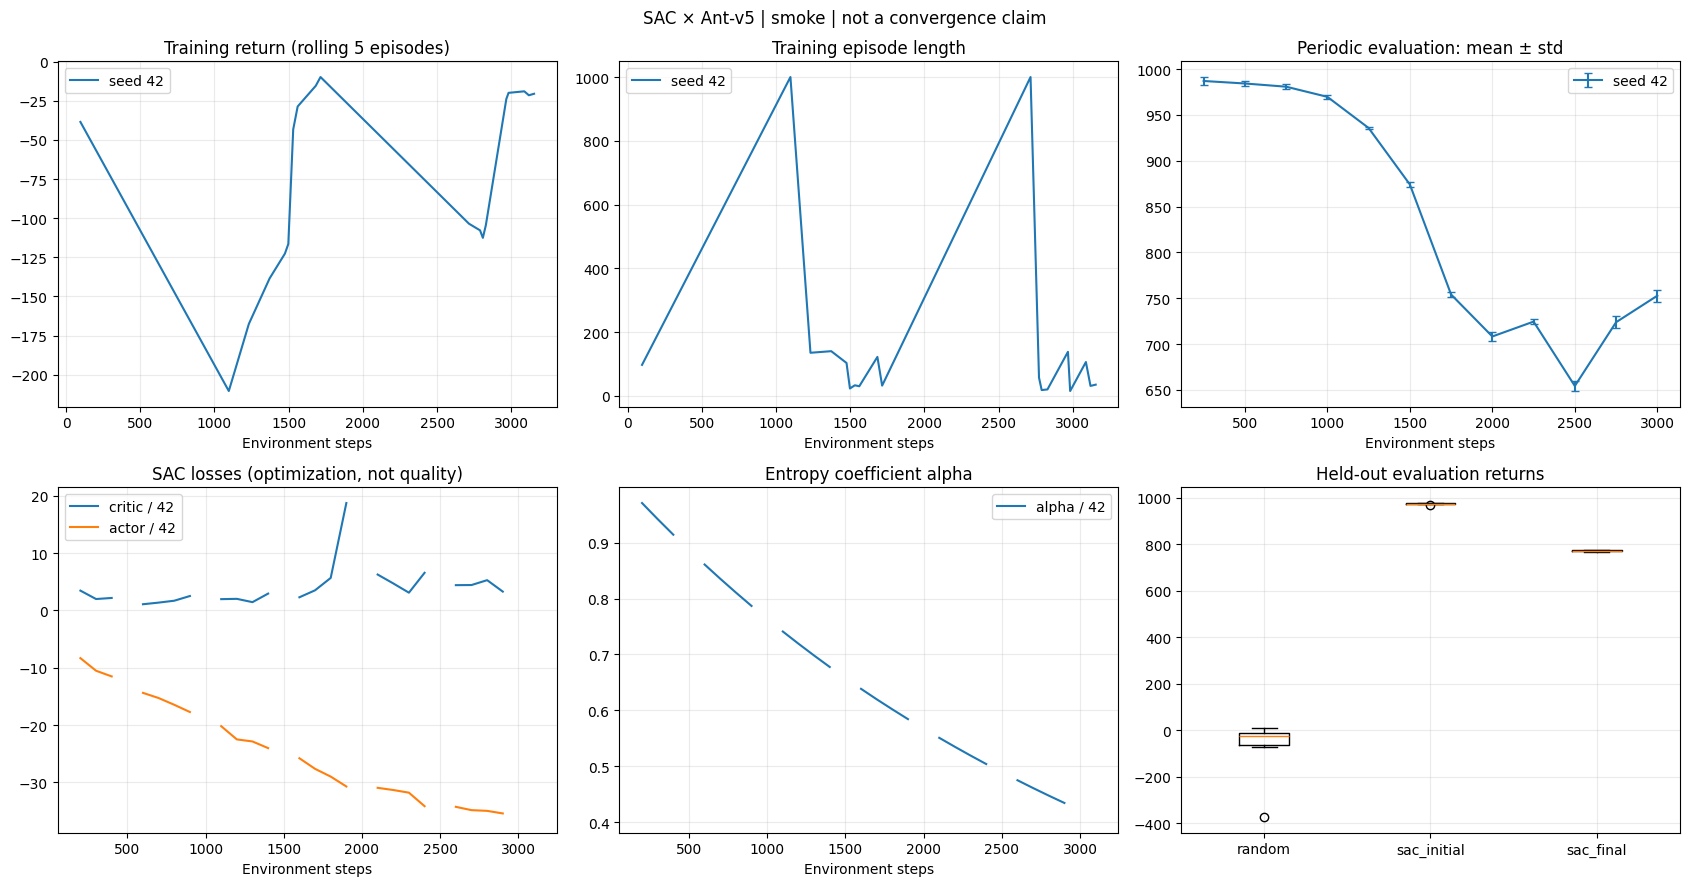

Paired final − initial mean: -202.46000285969384
This short run provides a descriptive comparison on the recorded evaluation episodes.


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for seed in run_objects:
    item = run_objects[seed]
    episodes = pd.DataFrame(item['audit'].episodes)
    losses = pd.DataFrame(item['audit'].losses)
    if not episodes.empty:
        axes[0, 0].plot(episodes.timestep, episodes.return_.rolling(5, min_periods=1).mean(), label=f'seed {seed}')
        axes[0, 1].plot(episodes.timestep, episodes.length, label=f'seed {seed}')

    archive_path = item['directory'] / 'eval' / 'evaluations.npz'
    if archive_path.exists():
        archive = np.load(archive_path)
        axes[0, 2].errorbar(archive['timesteps'], archive['results'].mean(axis=1),
            yerr=archive['results'].std(axis=1), label=f'seed {seed}', capsize=3)
    else:
        axes[0, 2].text(0.1, 0.5, 'Cutoff before first periodic evaluation', transform=axes[0, 2].transAxes)

    if 'train/critic_loss' in losses:
        axes[1, 0].plot(losses.timestep, losses['train/critic_loss'], label=f'critic / {seed}')
        axes[1, 0].plot(losses.timestep, losses['train/actor_loss'], label=f'actor / {seed}')
        axes[1, 1].plot(losses.timestep, losses['train/ent_coef'], label=f'alpha / {seed}')

labels = ['random', 'sac_initial', 'sac_final']
axes[1, 2].boxplot([results.loc[results.policy == p, 'return_'].to_numpy() for p in labels])
axes[1, 2].set_xticks([1, 2, 3], labels)

for ax, title in zip(axes.flat, ['Training return (rolling 5 episodes)', 'Training episode length',
    'Periodic evaluation: mean ± std', 'SAC losses (optimization, not quality)',
    'Entropy coefficient alpha', 'Held-out evaluation returns']):
    ax.set_title(title)
    ax.grid(alpha=0.25)
    if ax is not axes[1, 2]:
        ax.set_xlabel('Environment steps')
        ax.legend()

fig.suptitle(f'SAC × Ant-v5 | {MODE} | not a convergence claim')
fig.tight_layout()
fig.savefig(RUN_DIR / 'learning_curves.png', dpi=140)
plt.show()

paired = results.pivot(index=['training_seed', 'episode_seed'], columns='policy', values='return_')
paired['final_minus_initial'] = paired.sac_final - paired.sac_initial
paired.to_csv(RUN_DIR / 'paired_returns.csv')

print('Paired final − initial mean:', paired.final_minus_initial.mean())
print('This short run provides a descriptive comparison on the recorded evaluation episodes.')


## Recorded rollout video

Record the first final evaluation seed regardless of its outcome. The video uses the reloaded checkpoint, deterministic actions, and the same environment. Frames stream directly to disk to keep RAM usage low. A random or poorly trained Ant may fall during a valid rollout.

In [7]:
video_paths = []

for seed in run_objects:
    item = run_objects[seed]
    video_path = item['directory'] / 'rollout.mp4'
    video_env = make_env(render_mode='rgb_array')
    frames = 0
    try:
        obs, _ = video_env.reset(seed=seed + 100_000)
        fps = video_env.metadata['render_fps']

        with imageio.get_writer(str(video_path), fps=fps, codec='libx264',
                               quality=7, macro_block_size=16) as writer:
            first_frame = video_env.render()
            assert first_frame is not None and first_frame.ndim == 3
            writer.append_data(first_frame)
            frames += 1

            for _ in range(CFG['video_max_steps']):
                action, _ = item['model'].predict(obs, deterministic=True)
                obs, _, terminated, truncated, _ = video_env.step(action)
                writer.append_data(video_env.render())
                frames += 1
                if terminated or truncated:
                    break
    finally:
        video_env.close()

    assert frames > 1 and video_path.stat().st_size > 1024

    reader = imageio.get_reader(str(video_path))
    try:
        decoded = reader.get_data(0)
        assert decoded.ndim == 3 and decoded.shape[2] == 3
    finally:
        reader.close()

    video_paths.append(str(video_path))
    print(f'Video seed {seed}: {frames} frames, {video_path.stat().st_size:,} bytes')
    display(Video(str(video_path), embed=True, width=640))


Video seed 42: 1001 frames, 314,255 bytes


In [8]:
SUMMARY = dict(status='passed' if all(r['budget_completed'] for r in run_summaries) and len(run_summaries) == len(SEEDS) else 'partial', mode=MODE, runs=run_summaries, videos=video_paths,
    budget_completed=len(run_summaries) == len(SEEDS) and all(r['budget_completed'] for r in run_summaries),
    note='Smoke verifies optimization and pipeline, not convergence or statistically significant improvement.')

(RUN_DIR / 'summary.json').write_text(json.dumps(SUMMARY, indent=2))
(RUN_DIR / 'versions.txt').write_text('\n'.join(f'{p}=={v}' for p, v in VERSIONS.items()) + '\n')

assert (RUN_DIR / 'learning_curves.png').stat().st_size > 1024
assert len(results) == len(run_objects) * (CFG['baseline_episodes'] + 2 * CFG['eval_episodes'])

print('Pipeline finished; status:', SUMMARY['status'])
display(pd.DataFrame(run_summaries))
print('All artifacts:', RUN_DIR.resolve())

if MODE == 'smoke':
    print('Only the smoke test ran. Use a larger budget and multiple seeds for a substantive evaluation.')


PASS ? environment, gradient updates, weights, evaluation, checkpoint, replay buffer, plots, and MP4.


,seed,train_episodes,train_timesteps,gradient_updates,actor_weight_l2_change,train_seconds,replay_size,periodic_evaluations,random_return_mean,initial_return_mean,final_return_mean,checkpoint_reload_ok,replay_reload_ok
0,42,20,3154,3053,2.314187,68.204525,3153,12,-62.051346,974.15663,771.696627,True,True


All artifacts: /home/andreipc/Inno-RL/artifacts/ant_sac_smoke_20261021T184234215288Z
Only the smoke test ran. Use a larger budget and multiple seeds for a substantive evaluation.


## Next steps

1. Review return, episode length, and forward progress alongside the video. Use x-progress to distinguish forward locomotion from reward for remaining upright.
2. For a new full experiment, set `MODE = 'full'` in the configuration, restart the kernel, and run all cells.
3. For multiple independent runs, set `SEEDS = [42, 43, 44]`. The runs execute sequentially.

A new full run trains from scratch with larger networks. To continue **the same run** from its checkpoint, use `SAC.load(path, env=Monitor(make_env()))`, then `load_replay_buffer(...)` and `learn(..., reset_num_timesteps=False)`. Use multiple training seeds and a sufficient budget for statistically reliable conclusions.

**Artifacts** include configuration and package versions, Monitor CSVs, training episode, loss, and evaluation CSVs, periodic evaluations and the best checkpoint, the final model and replay buffer, paired comparisons, the `learning_curves.png` plot, the rollout MP4, and the summary JSON.